<a href="https://colab.research.google.com/github/Ariqq16/PCVK_Ganjil_2026/blob/main/P9/week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt
import os
from google.colab import drive

# Path folder image praktikum (sesuaikan dengan lokasi folder Anda di Drive)
BASE_PATH = '/content/drive/MyDrive/PCVK/Images/'
FACEDET_PATH = BASE_PATH + 'facedet/'
HAAR_PATH = BASE_PATH + 'haarcascades/'

6 Metode Template Matching OpenCV

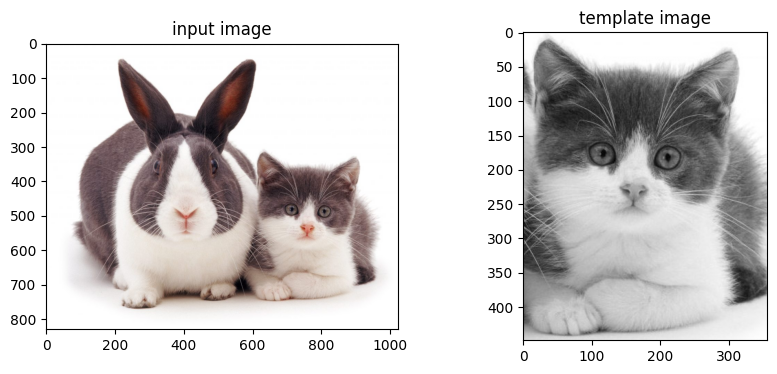

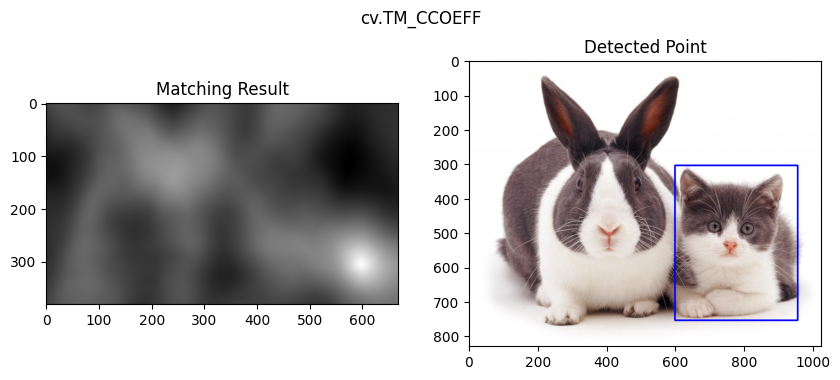

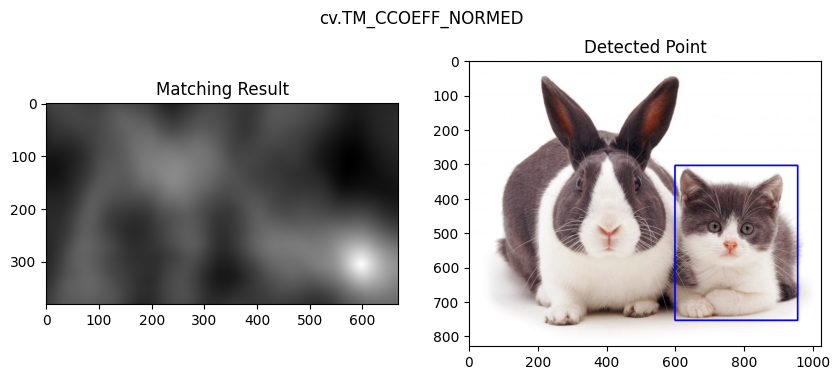

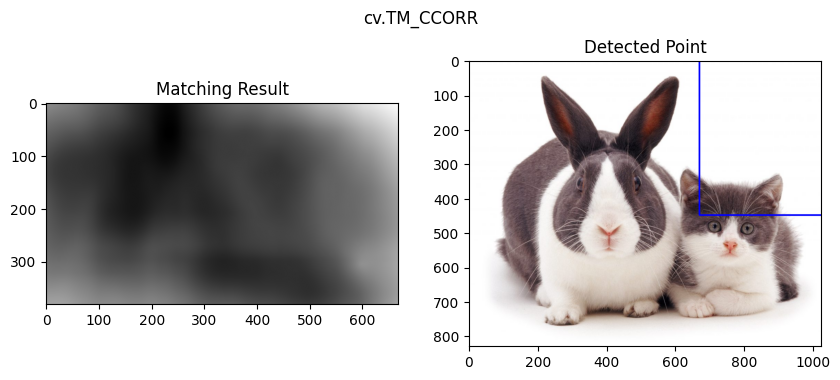

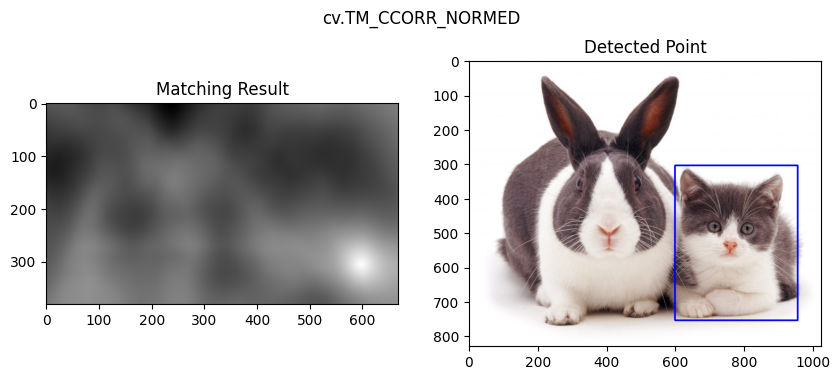

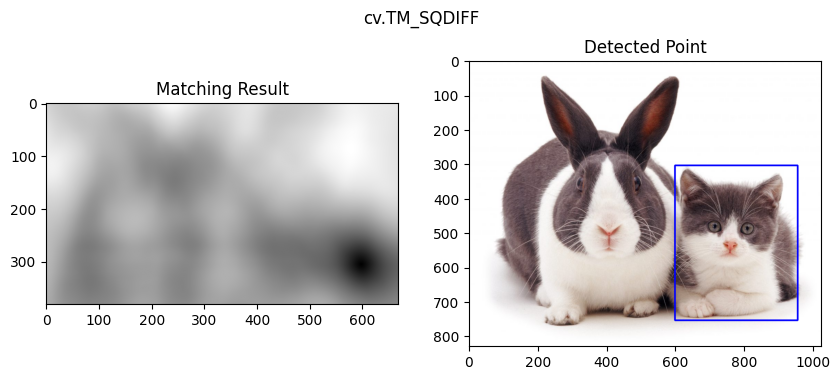

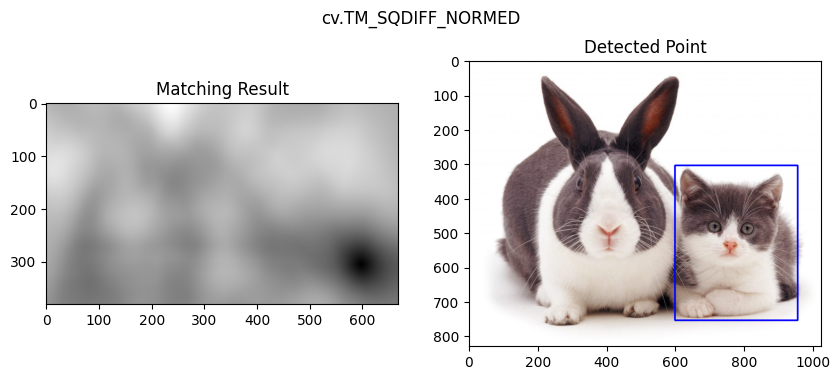

In [ ]:
img = cv.imread('/content/drive/MyDrive/PCVK_2026/cats_and_bunnies.jpg')
if img is None:
    img = cv.imread(BASE_PATH + 'cats_and_bunnies.jpg')

template = cv.imread('/content/drive/MyDrive/PCVK_2026/cat2_templatejpg.jpg', cv.IMREAD_GRAYSCALE)
if template is None:
    template = cv.imread(BASE_PATH + 'cat2_templatejpg.jpg', cv.IMREAD_GRAYSCALE)

if img is None or template is None:
    raise FileNotFoundError("Gambar atau template tidak ditemukan. Harap periksa kembali path file di Google Drive Anda.")

img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
w, h = template.shape[::-1]

methods = [
    ('cv.TM_CCOEFF', cv.TM_CCOEFF),
    ('cv.TM_CCOEFF_NORMED', cv.TM_CCOEFF_NORMED),
    ('cv.TM_CCORR', cv.TM_CCORR),
    ('cv.TM_CCORR_NORMED', cv.TM_CCORR_NORMED),
    ('cv.TM_SQDIFF', cv.TM_SQDIFF),
    ('cv.TM_SQDIFF_NORMED', cv.TM_SQDIFF_NORMED)
]

plt.figure(figsize=(10, 4))
plt.subplot(121), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)), plt.title('input image')
plt.subplot(122), plt.imshow(template, cmap='gray'), plt.title('template image')
plt.show()

for meth_name, meth in methods:
    img_copy = img.copy()
    res = cv.matchTemplate(img_gray, template, meth)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    if meth in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc

    bottom_right = (top_left[0] + w, top_left[1] + h)
    cv.rectangle(img_copy, top_left, bottom_right, (255, 0, 0), 3)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    fig.suptitle(meth_name)
    ax1.imshow(res, cmap='gray')
    ax1.set_title('Matching Result')
    ax2.imshow(cv.cvtColor(img_copy, cv.COLOR_BGR2RGB))
    ax2.set_title('Detected Point')
    plt.show()

Multiple Object Template Matching Tanpa Library OpenCV

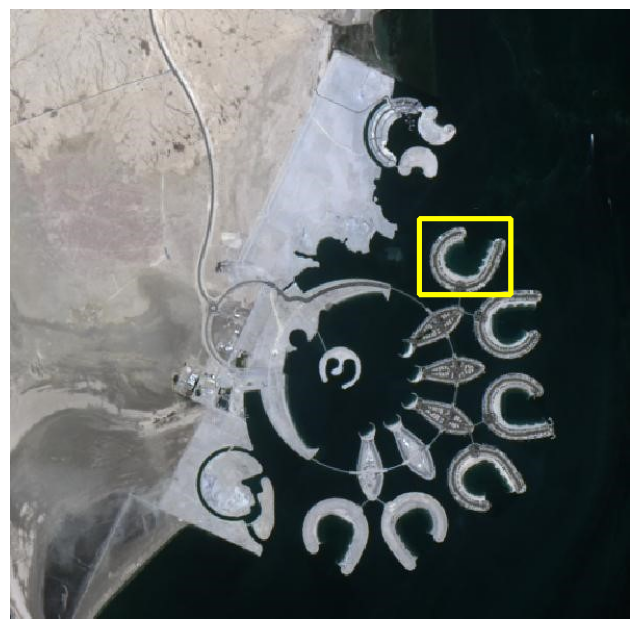

In [ ]:
img_b = cv.imread('/content/drive/MyDrive/PCVK_2026/bahrain.jpg')
if img_b is None:
    img_b = cv.imread(BASE_PATH + 'bahrain.jpg')

template_b = cv.imread('/content/drive/MyDrive/PCVK_2026/bahrain-template.jpg', cv.IMREAD_GRAYSCALE)
if template_b is None:
    template_b = cv.imread(BASE_PATH + 'bahrain-template.jpg', cv.IMREAD_GRAYSCALE)

if img_b is None or template_b is None:
    raise FileNotFoundError("Gambar 'bahrain.jpg' atau templatenya tidak ditemukan di Drive Anda. Harap periksa kembali lokasinya.")

img_gray = cv.cvtColor(img_b, cv.COLOR_BGR2GRAY)
H, W = img_gray.shape
ht, wt = template_b.shape

res_map = np.zeros((H - ht + 1, W - wt + 1), dtype=np.float32)
temp_norm = (template_b - np.mean(template_b)) / (np.std(template_b) + 1e-5)

for y in range(0, H - ht + 1, 3): # Step 3 piksel untuk mempercepat proses komputasi manual
    for x in range(0, W - wt + 1, 3):
        patch = img_gray[y:y+ht, x:x+wt]
        patch_norm = (patch - np.mean(patch)) / (np.std(patch) + 1e-5)
        res_map[y, x] = np.sum(patch_norm * temp_norm)

threshold = np.max(res_map) * 0.72
loc = np.where(res_map >= threshold)

img_out = img_b.copy()
detected_boxes = []

for pt in zip(*loc[::-1]):
    overlap = False
    for (bx, by) in detected_boxes:
        if abs(pt[0] - bx) < wt * 0.5 and abs(pt[1] - by) < ht * 0.5:
            overlap = True
            break
    if not overlap:
        detected_boxes.append((pt[0], pt[1]))
        cv.rectangle(img_out, (pt[0], pt[1]), (pt[0] + wt, pt[1] + ht), (0, 255, 255), 3)

plt.figure(figsize=(8, 8))
plt.imshow(cv.cvtColor(img_out, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

Sobel, Canny, dan Laplacian Edge Detection

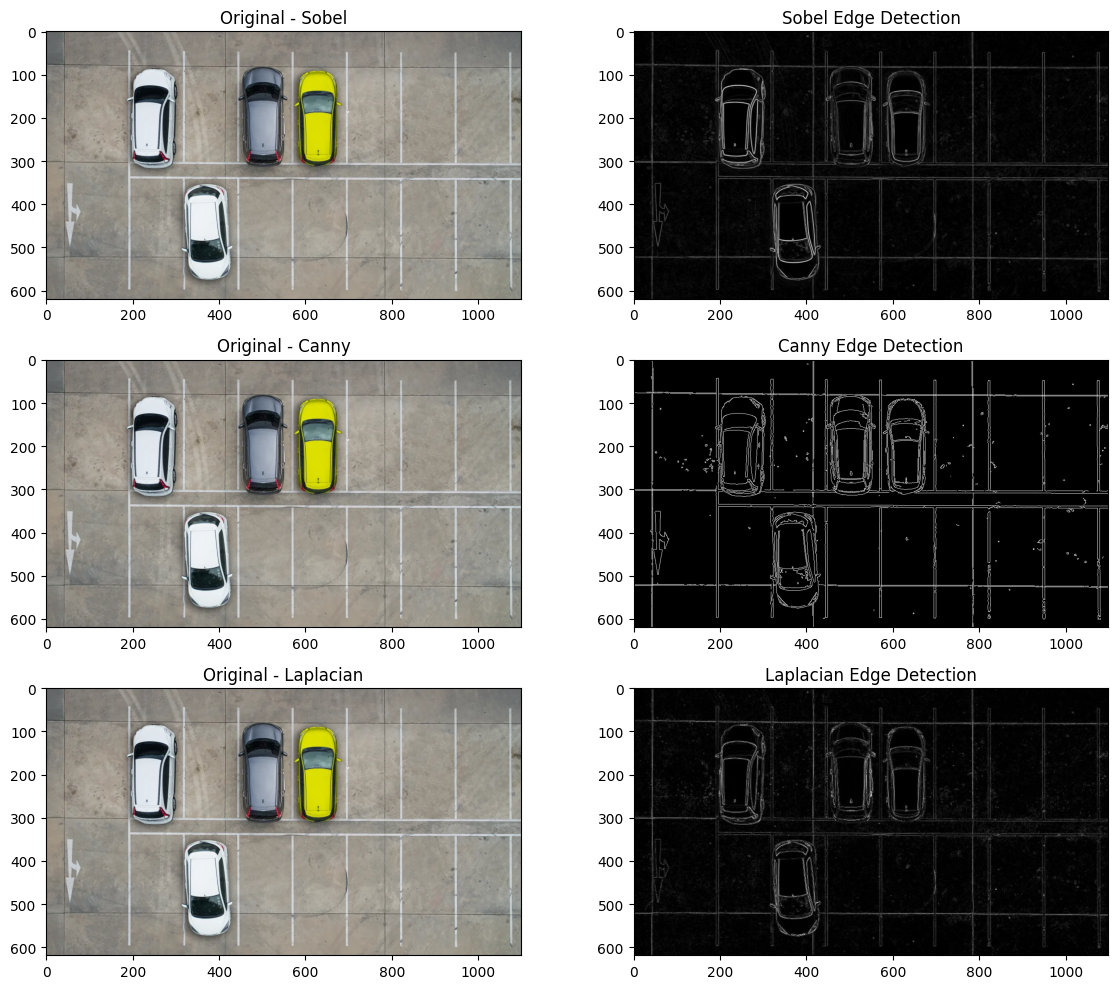

In [ ]:
img_park = cv.imread('/content/drive/MyDrive/PCVK_2026/car-park.jpg')
if img_park is None:
    img_park = cv.imread(BASE_PATH + 'car-park.jpg')

if img_park is None:
    raise FileNotFoundError("Gambar 'car-park.jpg' tidak ditemukan. Harap periksa kembali path file di Google Drive Anda.")

gray_park = cv.cvtColor(img_park, cv.COLOR_BGR2GRAY)

# a. Sobel Edge Detection
sobelx = cv.Sobel(gray_park, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(gray_park, cv.CV_64F, 0, 1, ksize=3)
sobel_combined = cv.magnitude(sobelx, sobely)

# b. Canny Edge Detection
canny = cv.Canny(gray_park, 100, 200)

# c. Laplacian Edge Detection
laplacian = cv.Laplacian(gray_park, cv.CV_64F)
laplacian = np.uint8(np.absolute(laplacian))

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

# Sobel
axes[0,0].imshow(cv.cvtColor(img_park, cv.COLOR_BGR2RGB)); axes[0,0].set_title('Original - Sobel')
axes[0,1].imshow(sobel_combined, cmap='gray'); axes[0,1].set_title('Sobel Edge Detection')

# Canny
axes[1,0].imshow(cv.cvtColor(img_park, cv.COLOR_BGR2RGB)); axes[1,0].set_title('Original - Canny')
axes[1,1].imshow(canny, cmap='gray'); axes[1,1].set_title('Canny Edge Detection')

# Laplacian
axes[2,0].imshow(cv.cvtColor(img_park, cv.COLOR_BGR2RGB)); axes[2,0].set_title('Original - Laplacian')
axes[2,1].imshow(laplacian, cmap='gray'); axes[2,1].set_title('Laplacian Edge Detection')

plt.tight_layout()
plt.show()

Harris Corner & Shi-Tomasi Corner Detection

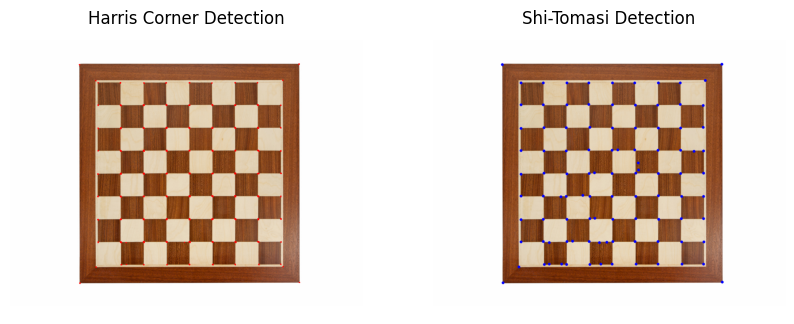

In [ ]:
img_chess = cv.imread('/content/drive/MyDrive/PCVK_2026/chess-board.jpg')
if img_chess is None:
    img_chess = cv.imread(BASE_PATH + 'chess-board.jpg')

if img_chess is None:
    raise FileNotFoundError("Gambar 'chess-board.jpg' tidak ditemukan. Harap periksa kembali path file di Google Drive Anda.")

gray_chess = cv.cvtColor(img_chess, cv.COLOR_BGR2GRAY)

# a. Harris Corner Detection
img_harris = img_chess.copy()
gray_f = np.float32(gray_chess)
dst = cv.cornerHarris(gray_f, blockSize=2, ksize=3, k=0.04)
dst = cv.dilate(dst, None)
img_harris[dst > 0.01 * dst.max()] = [0, 0, 255] # Tandai titik sudut dengan warna merah

# b. Shi-Tomasi Corner Detection
img_shi = img_chess.copy()
corners = cv.goodFeaturesToTrack(gray_chess, maxCorners=100, qualityLevel=0.01, minDistance=10)
corners = np.intp(corners) # Menggunakan np.intp sebagai pengganti np.int0 yang sudah dihapus di NumPy terbaru

for i in corners:
    x, y = i.ravel()
    cv.circle(img_shi, (x, y), 4, (255, 0, 0), -1) # Tandai titik sudut dengan lingkaran biru

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(cv.cvtColor(img_harris, cv.COLOR_BGR2RGB)); ax1.set_title('Harris Corner Detection'); ax1.axis('off')
ax2.imshow(cv.cvtColor(img_shi, cv.COLOR_BGR2RGB)); ax2.set_title('Shi-Tomasi Detection'); ax2.axis('off')
plt.show()

Grid Detection dengan Hough Transform

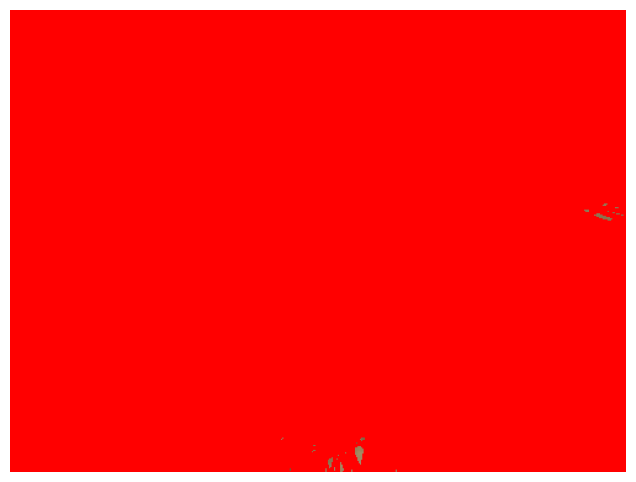

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Memperbaiki pembacaan path gambar secara aman
img_sudoku = cv.imread('/content/drive/MyDrive/PCVK_2026/sudoku.jpg')
if img_sudoku is None:
    img_sudoku = cv.imread(BASE_PATH + 'sudoku.jpg')

if img_sudoku is None:
    raise FileNotFoundError("Gambar 'sudoku.jpg' tidak ditemukan. Sila periksa lokasi file Anda.")

gray_sudoku = cv.cvtColor(img_sudoku, cv.COLOR_BGR2GRAY)

# 1. Canny
edges = cv.Canny(gray_sudoku, 50, 150, apertureSize=3)

# 2 & 3. Dilasi dan Erosi
kernel = np.ones((3,3), np.uint8)
dilated = cv.dilate(edges, kernel, iterations=1)
eroded = cv.erode(dilated, kernel, iterations=1)

# 4. HoughLines
lines = cv.HoughLines(eroded, 1, np.pi/180, 150)
img_hough = img_sudoku.copy()

if lines is not None:
    for line in lines:
        rho, theta = line[0]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * (a))
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * (a))
        cv.line(img_hough, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(8, 6))
plt.imshow(cv.cvtColor(img_hough, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

Contour Detection Menggunakan findContours()

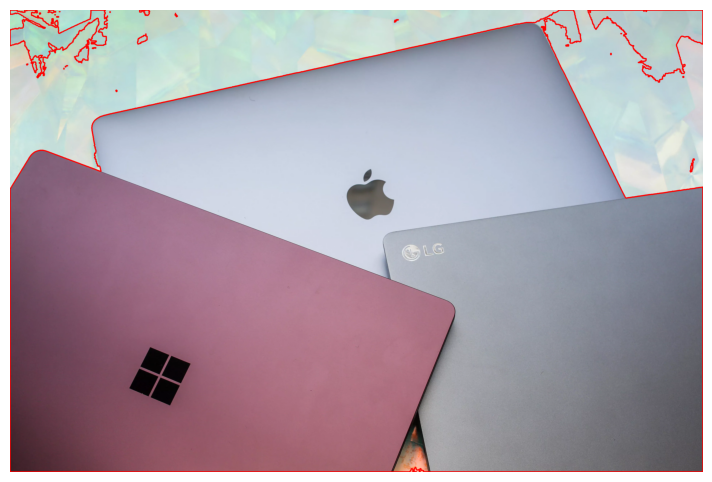

In [ ]:
img_laptop = cv.imread('/content/drive/MyDrive/PCVK_2026/laptop.jpg')
if img_laptop is None:
    img_laptop = cv.imread(BASE_PATH + 'laptop.jpg')

if img_laptop is None:
    raise FileNotFoundError("Gambar 'laptop.jpg' tidak ditemukan. Harap periksa kembali path file di Google Drive Anda.")

gray_laptop = cv.cvtColor(img_laptop, cv.COLOR_BGR2GRAY)

# Thresholding Biner
_, thresh_laptop = cv.threshold(gray_laptop, 200, 255, cv.THRESH_BINARY_INV)

# Find Contours
contours, _ = cv.findContours(thresh_laptop, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

img_contours = img_laptop.copy()
cv.drawContours(img_contours, contours, -1, (0, 0, 255), 5)

plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(img_contours, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

Face Detection pada Beberapa Objek Gambar

Model XML tidak ditemukan di Drive. Mengunduh otomatis dari GitHub OpenCV...
Unduhan selesai!


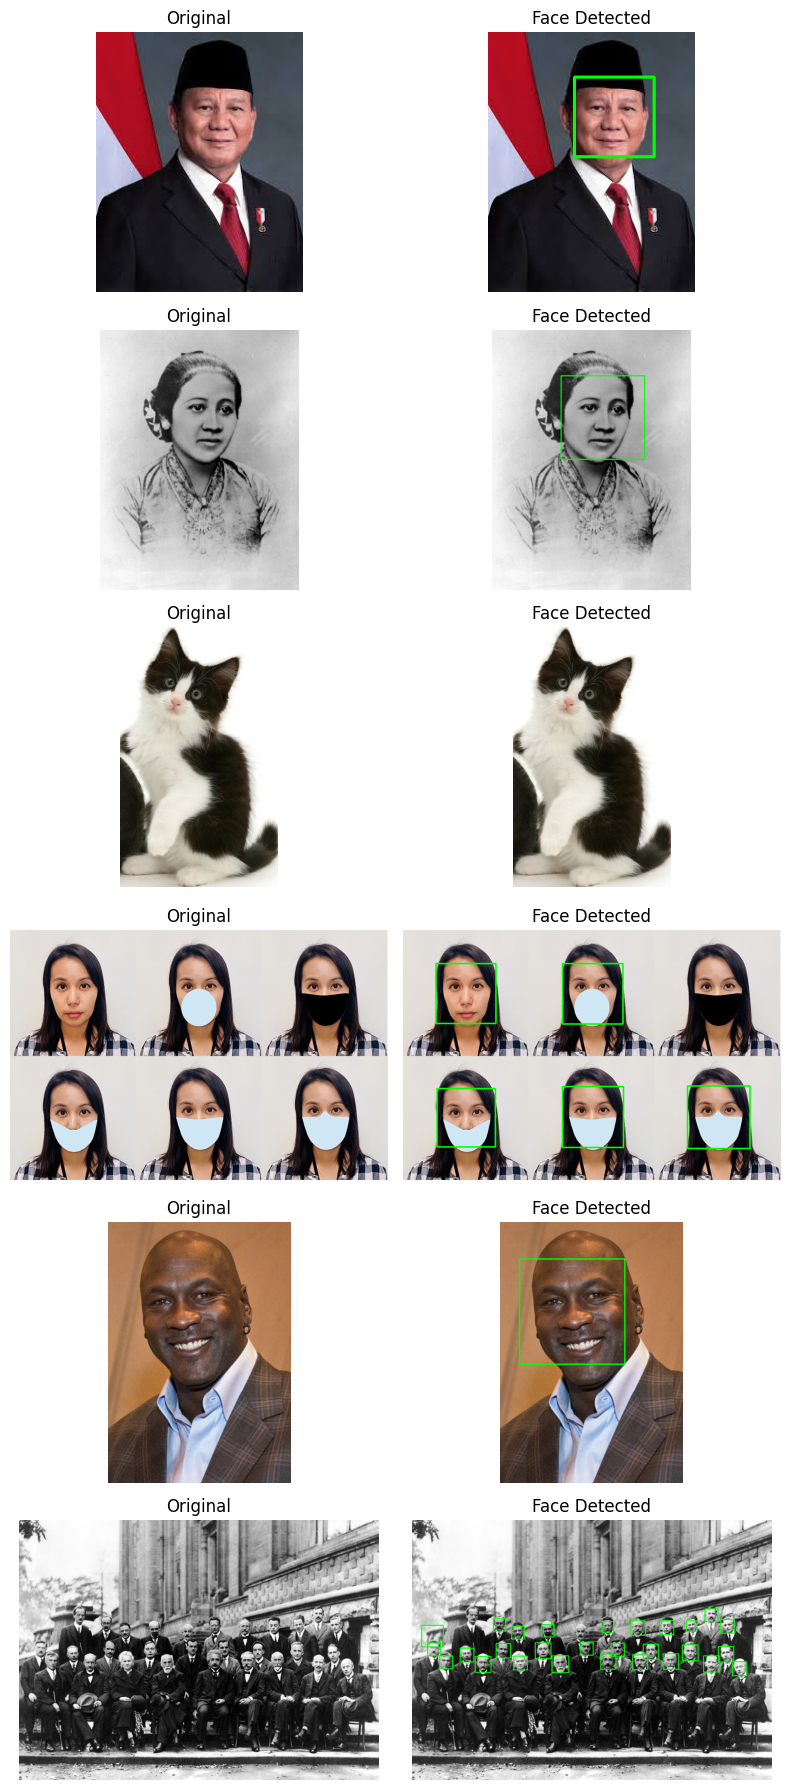

In [ ]:
import os
import urllib.request

# Tentukan lokasi penyimpanan model
cascade_path = HAAR_PATH + 'haarcascade_frontalface_alt.xml'

# Jika tidak ditemukan di path default, coba path alternatif di Drive
if not os.path.exists(cascade_path):
    cascade_path = '/content/drive/MyDrive/PCVK_2026/haarcascade_frontalface_alt.xml'

# Jika masih tidak ada di Drive, unduh langsung secara otomatis dari OpenCV GitHub
if not os.path.exists(cascade_path):
    print("Model XML tidak ditemukan di Drive. Mengunduh otomatis dari GitHub OpenCV...")
    os.makedirs(os.path.dirname(cascade_path) if os.path.dirname(cascade_path) else '.', exist_ok=True)
    url = "https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalface_alt.xml"
    try:
        urllib.request.urlretrieve(url, cascade_path)
        print("Unduhan selesai!")
    except Exception as e:
        # Jika folder Drive tidak dapat ditulis, unduh ke direktori lokal Colab
        cascade_path = 'haarcascade_frontalface_alt.xml'
        urllib.request.urlretrieve(url, cascade_path)
        print("Unduhan selesai (disimpan lokal di workspace Colab)!")

face_cascade = cv.CascadeClassifier(cascade_path)

image_files = ['prabowo.jpg', 'kartini.jpg', 'cat-template.jpg', 'mask.png', 'mjordan.jpg', 'solvayconf.jpg']

fig, axes = plt.subplots(len(image_files), 2, figsize=(8, 18))

for idx, fname in enumerate(image_files):
    # Mencoba membaca dari FACEDET_PATH terlebih dahulu, jika gagal coba path alternatif
    img_path = FACEDET_PATH + fname
    img_orig = cv.imread(img_path)

    if img_orig is None:
        # Mencoba membaca dari folder alternatif PCVK_2026
        img_path_alt = f'/content/drive/MyDrive/PCVK_2026/{fname}'
        img_orig = cv.imread(img_path_alt)

    if img_orig is None:
        print(f"Gambar {fname} tidak ditemukan di {img_path} maupun {img_path_alt}")
        continue

    gray = cv.cvtColor(img_orig, cv.COLOR_BGR2GRAY)
    img_det = img_orig.copy()

    # Deteksi Wajah menggunakan klasifikasi yang telah berhasil dimuat
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=4)
    for (x, y, w, h) in faces:
        cv.rectangle(img_det, (x, y), (x+w, y+h), (0, 255, 0), 2)

    axes[idx, 0].imshow(cv.cvtColor(img_orig, cv.COLOR_BGR2RGB)); axes[idx, 0].axis('off')
    axes[idx, 0].set_title("Original")
    axes[idx, 1].imshow(cv.cvtColor(img_det, cv.COLOR_BGR2RGB)); axes[idx, 1].axis('off')
    axes[idx, 1].set_title("Face Detected")

plt.tight_layout()
plt.show()

Deteksi Wajah Kucing

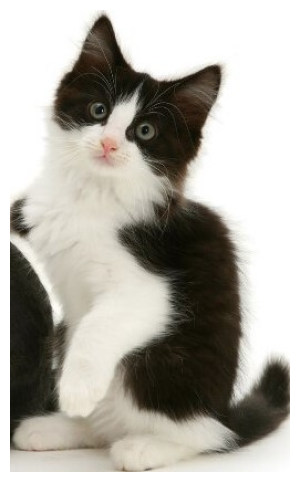

In [ ]:
import os
import urllib.request

# 1. Menentukan model cascade wajah kucing secara aman
cat_cascade_path = HAAR_PATH + 'haarcascade_frontalcatface.xml'
if not os.path.exists(cat_cascade_path):
    cat_cascade_path = '/content/drive/MyDrive/PCVK_2026/haarcascade_frontalcatface.xml'

# Unduh otomatis jika file klasifikasi wajah kucing belum ada di drive
if not os.path.exists(cat_cascade_path):
    print("Model XML wajah kucing tidak ditemukan di Drive. Mengunduh otomatis dari GitHub OpenCV...")
    url = "https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_frontalcatface.xml"
    try:
        os.makedirs(os.path.dirname(cat_cascade_path) if os.path.dirname(cat_cascade_path) else '.', exist_ok=True)
        urllib.request.urlretrieve(url, cat_cascade_path)
        print("Unduhan model kucing selesai!")
    except Exception as e:
        cat_cascade_path = 'haarcascade_frontalcatface.xml'
        urllib.request.urlretrieve(url, cat_cascade_path)
        print("Unduhan model kucing disimpan lokal di workspace Colab!")

cat_cascade = cv.CascadeClassifier(cat_cascade_path)

# 2. Pembacaan gambar secara aman tanpa penggabungan path absolut ganda
cat_img = cv.imread('/content/drive/MyDrive/PCVK_2026/cat-template.jpg')
if cat_img is None:
    cat_img = cv.imread(FACEDET_PATH + 'cat-template.jpg')

if cat_img is None:
    raise FileNotFoundError("Gambar 'cat-template.jpg' tidak ditemukan di Drive Anda. Harap periksa lokasinya.")

cat_gray = cv.cvtColor(cat_img, cv.COLOR_BGR2GRAY)

# 3. Deteksi Wajah Kucing
cats = cat_cascade.detectMultiScale(cat_gray, scaleFactor=1.05, minNeighbors=3)
for (x, y, w, h) in cats:
    cv.rectangle(cat_img, (x, y), (x+w, y+h), (255, 255, 255), 3)

plt.figure(figsize=(8, 6))
plt.imshow(cv.cvtColor(cat_img, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

Eye Detection pada Wajah Pak Prabowo

Model XML mata tidak ditemukan di Drive. Mengunduh otomatis dari GitHub OpenCV...
Unduhan model mata selesai!


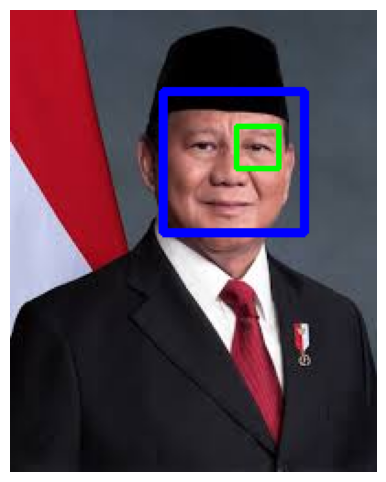

In [ ]:
import os
import urllib.request

# 1. Menentukan path model wajah dan mata secara aman
face_cascade_path = HAAR_PATH + 'haarcascade_frontalface_alt.xml'
if not os.path.exists(face_cascade_path):
    face_cascade_path = '/content/drive/MyDrive/PCVK_2026/haarcascade_frontalface_alt.xml'

eye_cascade_path = HAAR_PATH + 'haarcascade_eye.xml'
if not os.path.exists(eye_cascade_path):
    eye_cascade_path = '/content/drive/MyDrive/PCVK_2026/haarcascade_eye.xml'

# Unduh otomatis model mata jika belum tersedia
if not os.path.exists(eye_cascade_path):
    print("Model XML mata tidak ditemukan di Drive. Mengunduh otomatis dari GitHub OpenCV...")
    url_eye = "https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_eye.xml"
    try:
        os.makedirs(os.path.dirname(eye_cascade_path) if os.path.dirname(eye_cascade_path) else '.', exist_ok=True)
        urllib.request.urlretrieve(url_eye, eye_cascade_path)
        print("Unduhan model mata selesai!")
    except Exception as e:
        eye_cascade_path = 'haarcascade_eye.xml'
        urllib.request.urlretrieve(url_eye, eye_cascade_path)
        print("Unduhan model mata disimpan lokal di workspace Colab!")

face_cascade = cv.CascadeClassifier(face_cascade_path)
eye_cascade = cv.CascadeClassifier(eye_cascade_path)

# 2. Pembacaan gambar prabowo.jpg secara aman
prabowo = cv.imread('/content/drive/MyDrive/PCVK_2026/prabowo.jpg')
if prabowo is None:
    prabowo = cv.imread(FACEDET_PATH + 'prabowo.jpg')

if prabowo is None:
    raise FileNotFoundError("Gambar 'prabowo.jpg' tidak ditemukan. Harap periksa kembali lokasinya di Google Drive Anda.")

gray_p = cv.cvtColor(prabowo, cv.COLOR_BGR2GRAY)

# 3. Deteksi Wajah dan Deteksi Mata di dalam ROI (Region of Interest) wajah
faces = face_cascade.detectMultiScale(gray_p, scaleFactor=1.1, minNeighbors=4)
for (x, y, w, h) in faces:
    cv.rectangle(prabowo, (x, y), (x+w, y+h), (255, 0, 0), 3) # Kotak biru untuk wajah
    roi_gray = gray_p[y:y+h, x:x+w]
    roi_color = prabowo[y:y+h, x:x+w]

    eyes = eye_cascade.detectMultiScale(roi_gray, scaleFactor=1.1, minNeighbors=5)
    for (ex, ey, ew, eh) in eyes:
        cv.rectangle(roi_color, (ex, ey), (ex+ew, ey+eh), (0, 255, 0), 2) # Kotak hijau untuk mata

plt.figure(figsize=(6, 6))
plt.imshow(cv.cvtColor(prabowo, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

Deteksi Senyuman pada Gambar People

Model XML senyuman tidak ditemukan di Drive. Mengunduh otomatis dari GitHub OpenCV...
Unduhan model senyuman selesai!


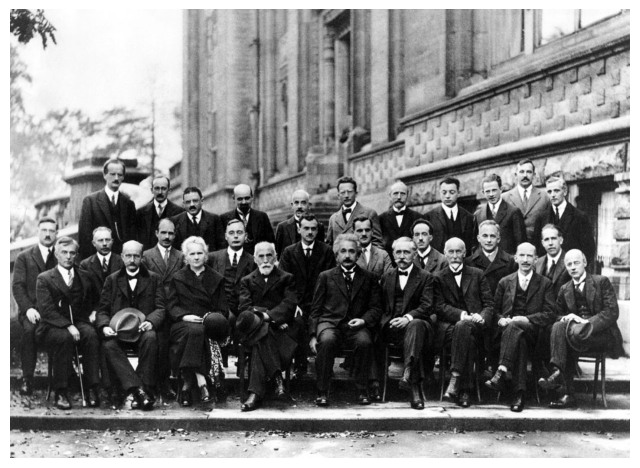

In [ ]:
import os
import urllib.request

# 1. Menentukan model cascade senyuman secara aman
smile_cascade_path = HAAR_PATH + 'haarcascade_smile.xml'
if not os.path.exists(smile_cascade_path):
    smile_cascade_path = '/content/drive/MyDrive/PCVK_2026/haarcascade_smile.xml'

# Unduh otomatis model senyuman jika belum tersedia di Drive
if not os.path.exists(smile_cascade_path):
    print("Model XML senyuman tidak ditemukan di Drive. Mengunduh otomatis dari GitHub OpenCV...")
    url_smile = "https://raw.githubusercontent.com/opencv/opencv/master/data/haarcascades/haarcascade_smile.xml"
    try:
        os.makedirs(os.path.dirname(smile_cascade_path) if os.path.dirname(smile_cascade_path) else '.', exist_ok=True)
        urllib.request.urlretrieve(url_smile, smile_cascade_path)
        print("Unduhan model senyuman selesai!")
    except Exception as e:
        smile_cascade_path = 'haarcascade_smile.xml'
        urllib.request.urlretrieve(url_smile, smile_cascade_path)
        print("Unduhan model senyuman disimpan lokal di workspace Colab!")

smile_cascade = cv.CascadeClassifier(smile_cascade_path)

# 2. Pembacaan gambar solvayconf.jpg secara aman tanpa path ganda
img_people = cv.imread('/content/drive/MyDrive/PCVK_2026/solvayconf.jpg')
if img_people is None:
    img_people = cv.imread(FACEDET_PATH + 'solvayconf.jpg')

if img_people is None:
    raise FileNotFoundError("Gambar 'solvayconf.jpg' tidak ditemukan. Harap periksa kembali lokasinya di Drive Anda.")

gray_people = cv.cvtColor(img_people, cv.COLOR_BGR2GRAY)

# 3. Deteksi Wajah dan Senyuman
faces = face_cascade.detectMultiScale(gray_people, 1.1, 5)
for (x, y, w, h) in faces:
    roi_gray = gray_people[y:y+h, x:x+w]
    roi_color = img_people[y:y+h, x:x+w]

    smiles = smile_cascade.detectMultiScale(roi_gray, scaleFactor=1.7, minNeighbors=20)
    for (sx, sy, sw, sh) in smiles:
        cv.rectangle(roi_color, (sx, sy), (sx+sw, sy+sh), (0, 0, 255), 2)

plt.figure(figsize=(8, 6))
plt.imshow(cv.cvtColor(img_people, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

Live Face Tracking via Kamera Web pada Google Colab


In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow
import base64

def video_stream():
  js = Javascript('''
    var video;
    var div = document.createElement('div');
    var stream;
    async function init() {
      video = document.createElement('video');
      video.style.display = 'block';
      stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
    }
    init();
    ''')
  display(js)

# Catatan: Jalankan snippet JavaScript standar Google Colab untuk mengakses webcam secara interaktif
print("Jalankan snippet webcam Colab dari Code Snippets menu 'Camera Capture'")

Jalankan snippet webcam Colab dari Code Snippets menu 'Camera Capture'


Blurring pada Bagian Wajah yang Terdeteksi

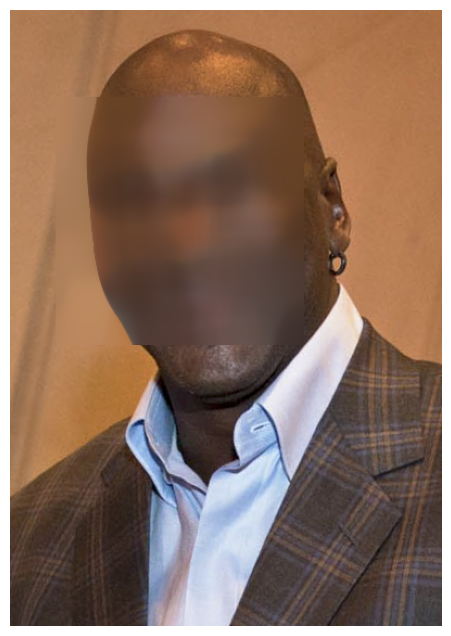

In [ ]:
import os

# 1. Pastikan model face_cascade telah terdefinisi dan tidak kosong
face_cascade_path = HAAR_PATH + 'haarcascade_frontalface_alt.xml'
if not os.path.exists(face_cascade_path):
    face_cascade_path = '/content/drive/MyDrive/PCVK_2026/haarcascade_frontalface_alt.xml'

if not os.path.exists(face_cascade_path):
    # Jika tidak ada, gunakan cascade lokal atau default
    face_cascade_path = 'haarcascade_frontalface_alt.xml'

face_cascade = cv.CascadeClassifier(face_cascade_path)

# 2. Pembacaan gambar mjordan.jpg secara aman
jordan = cv.imread('/content/drive/MyDrive/PCVK_2026/mjordan.jpg')
if jordan is None:
    jordan = cv.imread(FACEDET_PATH + 'mjordan.jpg')

if jordan is None:
    raise FileNotFoundError("Gambar 'mjordan.jpg' tidak ditemukan. Harap periksa kembali lokasinya di Google Drive Anda.")

gray_j = cv.cvtColor(jordan, cv.COLOR_BGR2GRAY)

# 3. Deteksi Wajah dan Proses Blurring
faces = face_cascade.detectMultiScale(gray_j, 1.1, 4)
for (x, y, w, h) in faces:
    # Crop ROI Wajah
    roi_face = jordan[y:y+h, x:x+w]
    # Lakukan medianBlur (ukuran kernel harus ganjil, misalnya 55)
    blurred_face = cv.medianBlur(roi_face, 55)
    # Timpa area wajah dengan citra blur
    jordan[y:y+h, x:x+w] = blurred_face

plt.figure(figsize=(6, 8))
plt.imshow(cv.cvtColor(jordan, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

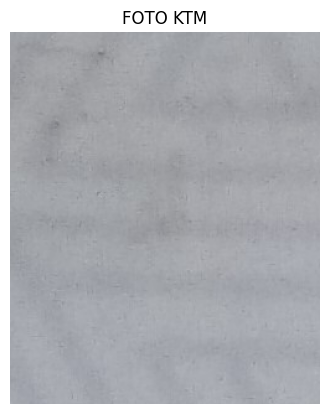

In [6]:
import cv2 as cv
import matplotlib.pyplot as plt

if 'BASE_PATH' not in globals():
    BASE_PATH = '/content/drive/MyDrive/PCVK/Images/'
if 'FACEDET_PATH' not in globals():
    FACEDET_PATH = BASE_PATH + 'facedet/'

ktm_img = cv.imread('/content/drive/MyDrive/PCVK_2026/KTM1d.jpg')
if ktm_img is None:
    ktm_img = cv.imread(FACEDET_PATH + 'ktm_sample.jpg')

if ktm_img is None:
    raise FileNotFoundError("Gambar KTM tidak ditemukan. Silakan periksa kembali file Anda di Drive.")

foto_ktm = ktm_img[200:500, 50:300]

plt.figure(figsize=(4, 5))
plt.imshow(cv.cvtColor(foto_ktm, cv.COLOR_BGR2RGB))
plt.title('FOTO KTM')
plt.axis('off')
plt.show()

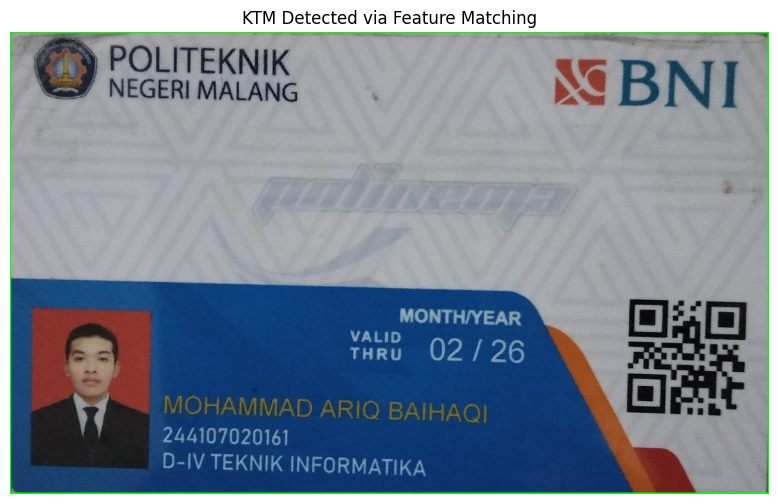

In [8]:
ktm_template = cv.imread('/content/drive/MyDrive/PCVK_2026/KTM.jpg', cv.IMREAD_GRAYSCALE)
if ktm_template is None:
    ktm_template = cv.imread(FACEDET_PATH + 'ktm_sample.jpg', cv.IMREAD_GRAYSCALE) # fallback template

scene_img = cv.imread('/content/drive/MyDrive/PCVK_2026/KTM1d.jpg')
if scene_img is None:
    scene_img = cv.imread(FACEDET_PATH + 'ktm_sample.jpg') # fallback jika tidak ditemukan

if ktm_template is None or scene_img is None:
    raise FileNotFoundError("Gambar template KTM atau Scene tidak ditemukan di Drive Anda.")

scene_gray = cv.cvtColor(scene_img, cv.COLOR_BGR2GRAY)

sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(ktm_template, None)
kp2, des2 = sift.detectAndCompute(scene_gray, None)

bf = cv.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)

good_matches = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

if len(good_matches) > 10:
    src_pts = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

    M, mask = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)
    h, w = ktm_template.shape
    pts = np.float32([[0, 0], [0, h-1], [w-1, h-1], [w-1, 0]]).reshape(-1, 1, 2)
    dst = cv.perspectiveTransform(pts, M)

    img_detected = cv.polylines(scene_img, [np.int32(dst)], True, (0, 255, 0), 4, cv.LINE_AA)

    plt.figure(figsize=(10, 6))
    plt.imshow(cv.cvtColor(img_detected, cv.COLOR_BGR2RGB))
    plt.title('KTM Detected via Feature Matching')
    plt.axis('off')
    plt.show()
else:
    print(f"Not enough matches are found - {len(good_matches)}/{10}")

In [12]:
import os
import cv2
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = "/content/drive/MyDrive/PCVK_2026" # satu subfolder per karakter: 0..9, A..Z
width, height = 100, 100

if not os.path.exists(DATADIR):
    raise FileNotFoundError(
        f"Folder '{DATADIR}' tidak ditemukan! Silakan unggah dataset Anda ke Colab, "
        "ekstrak file zip dataset, atau sesuaikan path DATADIR ke lokasi Drive Anda."
    )

dirs = sorted(os.listdir(DATADIR)) # daftar nama kelas
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    if not os.path.isdir(path):
        continue
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_GRAYSCALE)
            if img_array is not None:
                new_array = cv2.resize(img_array, (width, height))
                training_data.append([new_array, class_number])
        except Exception:
            pass

if len(training_data) == 0:
    print("Peringatan: Tidak ada gambar yang berhasil dibaca dari dataset.")
else:
    random.shuffle(training_data)
    X, Y = [], []
    for feature, label in training_data:
        X.append(feature)
        Y.append(label)

    X = np.array(X).reshape(-1, width, height, 1)
    Y = np.array(Y)

    pickle.dump(X, open("X.pickle", "wb"))
    pickle.dump(Y, open("Y.pickle", "wb"))
    pickle.dump(dirs, open("kelas.pickle", "wb"))

    print("jumlah data :", len(training_data))
    print("jumlah kelas:", len(dirs), dirs)

noises: 100%|██████████| 101/101 [00:00<00:00, 235.86it/s]

jumlah data : 100
jumlah kelas: 48 ['KTM.jpg', 'KTM1a.jpg', 'KTM1b.jpg', 'KTM1c.jpg', 'KTM1d.jpg', 'bahrain-template.jpg', 'bahrain.jpg', 'car-park.jpg', 'cat-and-rabbit.jpg', 'cat-template.jpg', 'cat2_templatejpg.jpg', 'cats_and_bunnies.jpg', 'chess-board.jpg', 'couple.tiff', 'crayfish.jpg', 'djawatan.jpg', 'galaxy.jpg', 'gradient.jpg', 'haarcascade_eye.xml', 'haarcascade_frontalcatface.xml', 'haarcascade_frontalface_alt.xml', 'haarcascade_smile.xml', 'houses.jpg', 'kartini.jpg', 'kitten01.jpg', 'ktp.jpg', 'ktp_ariq.jpeg', 'ktp_fulan.jpg', 'ktp_fulani.jpg', 'laptop.jpg', 'lena.jpg', 'lena_gs_lc2.jpg', 'lena_lc.jpg', 'lily.jpg', 'mandrill.tiff', 'mask.png', 'mjordan.jpg', 'noises', 'parking-lot-cars (1).jpg', 'parking-lot-cars.jpg', 'peppers.jpg', 'plat_nomor.jpeg', 'prabowo.jpg', 'solvayconf.jpg', 'sudoku-original (1).jpg', 'sudoku-original.jpg', 'sudoku.jpg', 'sunset.jpg']


In [13]:
import pickle
from keras.layers import (Input, Conv2D, MaxPooling2D,
Flatten, Dense, ZeroPadding2D)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical
X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))
Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]
inputs = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)
model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
loss='categorical_crossentropy',
metrics=['accuracy'])
riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save('anpr.keras')
print("akurasi training :", riwayat.history['accuracy'][-1])
print("akurasi validasi :", riwayat.history['val_accuracy'][-1])

Epoch 1/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 709ms/step - accuracy: 0.6000 - loss: 3.3877 - val_accuracy: 1.0000 - val_loss: 2.8622
Epoch 2/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 450ms/step - accuracy: 1.0000 - loss: 2.6462 - val_accuracy: 1.0000 - val_loss: 2.0109
Epoch 3/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 973ms/step - accuracy: 1.0000 - loss: 1.7586 - val_accuracy: 1.0000 - val_loss: 1.0590
Epoch 4/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 821ms/step - accuracy: 1.0000 - loss: 0.8378 - val_accuracy: 1.0000 - val_loss: 0.3297
Epoch 5/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 478ms/step - accuracy: 1.0000 - loss: 0.2323 - val_accuracy: 1.0000 - val_loss: 0.0600
Epoch 6/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 486ms/step - accuracy: 1.0000 - loss: 0.0408 - val_accuracy: 1.0000 - val_loss: 0.0097
Epoch 7/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 464ms/step - accuracy: 1.0000 - loss: 0.0067 - val_accuracy: 1.0000 - val_loss: 0.0018
Epoch 8/20
3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 502ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 1.0000 - val_loss: